# What moves YPF's stock? Argentine macro risk vs. global energy

**Author:** Matías Batalla · B.A. in Economics, Universidad Nacional Arturo Jauretche (undergraduate thesis research)

This notebook reproduces the final regression of the thesis chapter on YPF S.A. It estimates how YPF's monthly ADR return relates to two **domestic** risk factors (Argentine country risk and the CCL exchange rate) and two **global** factors (Brent crude and the US energy sector), controlling for systemic and regulatory shocks.

**Model** (OLS, monthly, May 2000 – Sep 2025, N = 305):

$$r^{YPF}_t = \alpha + \beta_1\,\Delta EMBI_t + \beta_2\,\Delta\ln Brent_t + \beta_3\,\Delta\ln CCL_t + \beta_4\,Energy^{net}_t + \gamma_1 D^{sys}_t + \gamma_2 D^{reg}_t + \varepsilon_t$$

- $\Delta EMBI$: monthly change in country risk (in units of 100 basis points)
- $Energy^{net}$: S&P 500 Energy log return, orthogonalized to Brent (residual of regressing it on Brent)
- $D^{sys}$: systemic shocks (Feb 2009, Mar 2020); $D^{reg}$: expropriation of Repsol's stake (Apr 2012)

Standard errors are heteroskedasticity-robust (White/HC1). The estimator is written out with NumPy so every step is visible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

base = pd.read_csv("../data/model_base.csv", parse_dates=["month"])
monthly = pd.read_csv("../data/ypf_monthly.csv", parse_dates=["month"])
# Country risk is expressed per 100 bp so its coefficient is readable
base["country_risk_change_100bp"] = base["country_risk_change_bp"] / 100
print(base.shape, base["month"].min().date(), "to", base["month"].max().date())
base.head()

(305, 9) 2000-05-01 to 2025-09-01


,month,ypf_return,country_risk_change_bp,brent_log_change,ccl_log_change,us_energy_net_of_oil,systemic_dummy,regulatory_dummy,country_risk_change_100bp
0,2000-05-01,0.0322,89.0069,0.1698,0.0000,0.0052,0,0,0.8901
1,2000-06-01,0.1489,-10.9901,0.0768,0.0000,-0.0923,0,0,-0.1099
2,2000-07-01,-0.0445,-24.3701,-0.1268,0.0000,0.0335,0,0,-0.2437
3,2000-08-01,-0.0393,40.7081,0.1637,0.0000,-0.0087,0,0,0.4071
4,2000-09-01,-0.1170,-6.5652,-0.0611,0.0000,0.0570,0,0,-0.0657


## 1. OLS with robust (HC1) standard errors

In [2]:
def ols(df, y, xs, robust=True):
    # OLS with White/HC1 standard errors (classical if robust=False).
    X = np.column_stack([np.ones(len(df))] + [df[x].to_numpy(float) for x in xs])
    Y = df[y].to_numpy(float)
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ Y
    e = Y - X @ beta
    if robust:
        meat = X.T @ (X * (e ** 2)[:, None])
        cov = XtX_inv @ meat @ XtX_inv * n / (n - k)   # HC1 small-sample correction
    else:
        cov = XtX_inv * (e @ e) / (n - k)
    se = np.sqrt(np.diag(cov))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    tcrit = stats.t.ppf(0.975, n - k)
    r2 = 1 - (e @ e) / np.sum((Y - Y.mean()) ** 2)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k)
    table = pd.DataFrame({"coef": beta, "std_err": se, "t": t, "p_value": p,
                          "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se},
                         index=["const"] + xs)
    return table, {"n": n, "r2": r2, "adj_r2": adj_r2}

In [3]:
X_FINAL = ["country_risk_change_100bp", "brent_log_change", "ccl_log_change",
           "us_energy_net_of_oil", "systemic_dummy", "regulatory_dummy"]

robust_tab, fit = ols(base, "ypf_return", X_FINAL, robust=True)
classic_tab, _ = ols(base, "ypf_return", X_FINAL, robust=False)

# The dummies flag only 1-2 months each: their residuals are ~0, so the robust
# error collapses. As in the thesis, report classical errors for the dummies.
final = robust_tab.copy()
dummies = ["systemic_dummy", "regulatory_dummy"]
final.loc[dummies] = classic_tab.loc[dummies]

print(f"N = {fit['n']}   R² = {fit['r2']:.3f}   adj. R² = {fit['adj_r2']:.3f}")
final

N = 305   R² = 0.356   adj. R² = 0.343


,coef,std_err,t,p_value,ci_low,ci_high
const,0.0117,0.0070,1.6595,0.0981,-0.0022,0.0256
country_risk_change_100bp,-0.0036,0.0022,-1.6855,0.0929,-0.0079,0.0006
brent_log_change,0.3993,0.0759,5.2577,0.0000,0.2498,0.5488
ccl_log_change,-0.4153,0.1118,-3.7138,0.0002,-0.6354,-0.1952
us_energy_net_of_oil,0.7262,0.1386,5.2387,0.0000,0.4534,0.9991
systemic_dummy,-0.2677,0.0919,-2.9131,0.0038,-0.4485,-0.0868
regulatory_dummy,-0.6600,0.1213,-5.4410,0.0000,-0.8987,-0.4213


The estimates match Table 4.2 of the thesis (adj. R² 0.343; Brent 0.399, CCL −0.415, US energy net of oil 0.726, all with p < 0.001; country risk −0.0036 per 100 bp, p = 0.093).

## 2. Which factor matters most? Effect of a typical month

Coefficients are in different units, so each one is multiplied by the standard deviation of its variable: the result is the change in YPF's monthly log return associated with a one-standard-deviation move, holding the other factors fixed.

In [4]:
labels = {"country_risk_change_100bp": "Country risk (EMBI, per 100 bp)",
          "brent_log_change": "Brent oil",
          "ccl_log_change": "CCL exchange rate",
          "us_energy_net_of_oil": "US energy sector (net of oil)"}
group = {"country_risk_change_100bp": "domestic", "ccl_log_change": "domestic",
         "brent_log_change": "global", "us_energy_net_of_oil": "global"}

effects = pd.DataFrame({
    "factor": [labels[x] for x in labels],
    "group": [group[x] for x in labels],
    "effect_1sd": [final.loc[x, "coef"] * base[x].std() for x in labels],
    "p_value": [final.loc[x, "p_value"] for x in labels],
}).sort_values("effect_1sd", key=np.abs, ascending=False)
effects

,factor,group,effect_1sd,p_value
3,US energy sector (net of oil),global,0.0392,0.0000
1,Brent oil,global,0.0387,0.0000
2,CCL exchange rate,domestic,-0.0345,0.0002
0,"Country risk (EMBI, per 100 bp)",domestic,-0.0126,0.0929


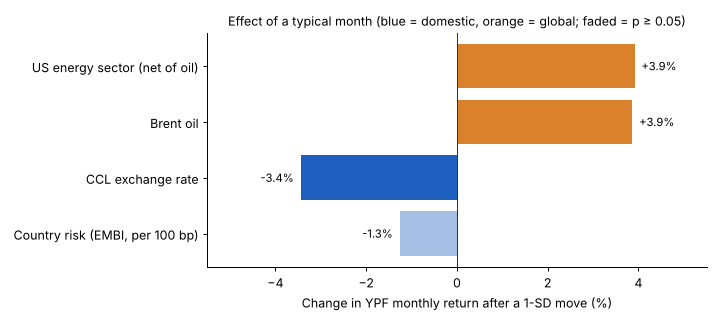

In [5]:
colors = {"domestic": "#1f5fbf", "global": "#d9822b"}
fig, ax = plt.subplots(figsize=(8, 3.6))
eff = effects.iloc[::-1]
from matplotlib.colors import to_rgba
ax.barh(eff["factor"], eff["effect_1sd"] * 100,
        color=[to_rgba(colors[g], 1 if p < 0.05 else 0.4) for g, p in zip(eff["group"], eff["p_value"])])
ax.axvline(0, color="#333", lw=0.8)
for i, v in enumerate(eff["effect_1sd"] * 100):
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("Change in YPF monthly return after a 1-SD move (%)")
ax.set_title("Effect of a typical month (blue = domestic, orange = global; faded = p ≥ 0.05)", fontsize=10)
ax.set_xlim(-5.5, 5.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/effects.png", dpi=160)
plt.show()

## 3. Context: YPF's price and the shocks in the sample

Annualized volatility: 51.6%
Maximum drawdown: -95.3%


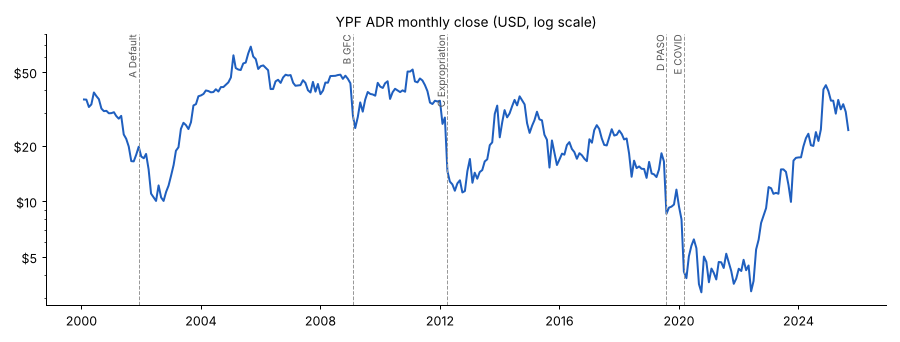

In [6]:
events = {"2001-12": "A Default", "2009-02": "B GFC", "2012-04": "C Expropriation",
          "2019-08": "D PASO", "2020-03": "E COVID"}
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(monthly["month"], monthly["ypf_adr_usd"], color="#1f5fbf", lw=1.6)
ax.set_yscale("log")
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([5, 10, 20, 50]); ax.set_yticklabels(["$5", "$10", "$20", "$50"])
for m, lab in events.items():
    d = pd.Timestamp(m + "-01")
    ax.axvline(d, color="#999", ls="--", lw=0.8)
    ax.text(d, ax.get_ylim()[1], lab, rotation=90, va="top", ha="right", fontsize=8, color="#555")
ax.set_title("YPF ADR monthly close (USD, log scale)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/ypf_price.png", dpi=160)
plt.show()

r = monthly["ypf_return_log"].dropna()
peak = monthly["ypf_adr_usd"].cummax()
print(f"Annualized volatility: {r.std() * np.sqrt(12):.1%}")
print(f"Maximum drawdown: {(monthly['ypf_adr_usd'] / peak - 1).min():.1%}")

## 4. YPF's return against the CCL

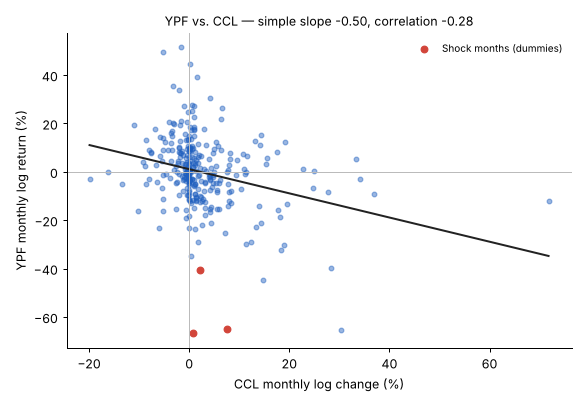

In [7]:
shock = (base["systemic_dummy"] == 1) | (base["regulatory_dummy"] == 1)
x, y = base["ccl_log_change"], base["ypf_return"]
slope, intercept, corr, *_ = stats.linregress(x, y)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(x[~shock] * 100, y[~shock] * 100, s=14, alpha=0.45, color="#1f5fbf")
ax.scatter(x[shock] * 100, y[shock] * 100, s=28, color="#d2453a", label="Shock months (dummies)")
xx = np.linspace(x.min(), x.max(), 50)
ax.plot(xx * 100, (intercept + slope * xx) * 100, color="#222", lw=1.6)
ax.axhline(0, color="#bbb", lw=0.8); ax.axvline(0, color="#bbb", lw=0.8)
ax.set_xlabel("CCL monthly log change (%)"); ax.set_ylabel("YPF monthly log return (%)")
ax.set_title(f"YPF vs. CCL — simple slope {slope:.2f}, correlation {corr:.2f}", fontsize=10)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/scatter_ccl.png", dpi=160)
plt.show()

## 5. Robustness

A few alternative specifications that can be rebuilt from this dataset. The full set of 15 specifications from the thesis is in `data/robustness.csv`.

In [8]:
def spec(name, df, xs):
    tab, f = ols(df, "ypf_return", xs)
    row = {"specification": name, "N": f["n"], "adj_r2": f["adj_r2"]}
    for x in ["country_risk_change_100bp", "brent_log_change", "ccl_log_change", "us_energy_net_of_oil"]:
        row["p_" + x.split("_")[0]] = tab.loc[x, "p_value"] if x in xs else np.nan
    return row

no_sector = [x for x in X_FINAL if x != "us_energy_net_of_oil"]
rows = [
    spec("Final model", base, X_FINAL),
    spec("Without US energy sector", base, no_sector),
    spec("Without sector or CCL", base, [x for x in no_sector if x != "ccl_log_change"]),
    spec("Excluding January 2002", base[base["month"] != "2002-01-01"], X_FINAL),
    spec("From January 2006 (post-default)", base[base["month"] >= "2006-01-01"],
         [x for x in X_FINAL if x != "systemic_dummy"] + ["systemic_dummy"]),
]
rob = pd.DataFrame(rows).set_index("specification")
rob

,N,adj_r2,p_country,p_brent,p_ccl,p_us
specification,,,,,,
Final model,305,0.3429,0.0929,0.0000,0.0002,0.0000
Without US energy sector,305,0.2789,0.1178,0.0000,0.0002,NaN
Without sector or CCL,305,0.2196,0.0715,0.0000,NaN,NaN
Excluding January 2002,304,0.3478,0.1057,0.0000,0.0001,0.0000
From January 2006 (post-default),237,0.3983,0.0046,0.0436,0.0008,0.0000


In [9]:
thesis = pd.read_csv("../data/robustness.csv")
thesis[["specification", "n_obs", "p_country_risk", "p_brent", "p_ccl", "p_us_energy", "adj_r2"]]

,specification,n_obs,p_country_risk,p_brent,p_ccl,p_us_energy,adj_r2
0,Final model,305,0.0929,0.0000,0.0002,0.0000,0.3429
1,US energy sector not netted of oil,305,0.0929,0.5065,0.0002,0.0000,0.3429
2,Without US energy sector,305,0.1178,0.0000,0.0002,NaN,0.2789
3,Without sector or CCL,305,0.0715,0.0000,NaN,NaN,0.2196
4,Official FX instead of CCL,305,0.0657,0.0000,0.0597,0.0000,0.3062
5,CCL with no link to YPF quotes,304,0.0908,0.0000,0.0006,0.0000,0.3394
6,Implied CCL (YPFD/ADR) full sample,305,0.1646,0.0000,0.0000,0.0000,0.3567
7,Excluding January 2002,304,0.1057,0.0000,0.0001,0.0000,0.3478
8,"Extra dummies: PASO 2019, Sep 2020",305,0.0678,0.0000,0.0001,0.0000,0.3841
9,From January 2006 (post-default),237,0.0046,0.0084,0.0008,0.0000,0.3983


The rebuilt specifications match the thesis table. In the post-2006 sample the fit and the CCL and country-risk results are identical, but Brent's p-value differs (0.044 here vs. 0.008 in the thesis): the thesis re-nets the energy sector against Brent within the subsample, which reassigns the shared oil component without changing the fit.

## 6. Takeaways

- The model explains about a third of the monthly variance of YPF's return (adj. R² ≈ 0.34).
- A typical month in **Brent** or in the **US energy sector** goes with roughly a ±3.9% move in YPF's return; a typical **CCL** jump with about −3.4%. Global and domestic currency factors carry similar weight.
- **Country risk** is weak on the full sample (p ≈ 0.09) but becomes significant once the 2001–2005 default and debt-restructuring years are excluded.
- The results are consistent with the market pricing YPF both as a global oil company and as an Argentine peso asset. They describe statistical association, not causation.

**Data sources:** Investing.com (YPF ADR, Brent, S&P 500 Energy), Rava Bursátil (JP Morgan EMBI Argentina), BCRA (official exchange rate), valordolarblue and Rava (CCL). The CCL is a spliced series: official BCRA rate changes before Dec 2009, the CCL implied by YPF's local share and ADR from Dec 2009 to Jul 2013, and the market CCL from Aug 2013.